# AUPRC by number of 2019 wetland pixels per cell

Validation AUPRC for the hurdle classifier (any 2019 wetland in the cell developed by 2024, `n_developed > 0`), split by how many 30m wetland pixels the cell held in 2019. One figure per cell size, read from `results/hurdle_clf_mlp_{300m,3km}/auprc_by_n_wetland.csv`.

Each bar is the mean over the 5 spatial folds and the error bar is the standard deviation across folds. The gray line across each bar is the positive rate in that bin, which is the AUPRC a random ranking would get. Since the positive rate moves a lot across bins, compare each bar to its own gray line, not across bins.

The 300m CSV also scores the TCN share regressor, but only the classifier is plotted here.

The bins are the same at both resolutions, so at 3km almost every cell lands in 91+. The "1" bin at 3km has positives in only 2 of 5 folds (3 folds have AUPRC undefined), so that bar is a mean over 2 folds and a handful of cells, and its std comes from just those 2.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUNS = {
    "300m": ROOT / "results/hurdle_clf_mlp_300m",
    "3km": ROOT / "results/hurdle_clf_mlp_3km",
}
FIG_DIR = ROOT / "results/figures/prediction_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)
BIN_ORDER = ["1", "2 to 15", "16 to 44", "45 to 90", "91+"]

auprc = {}
for res, d in RUNS.items():
    m = json.loads((d / "manifest.json").read_text())
    c = m["cells"]
    print(f"{res:>5}  {m['model']}  {m['loss']}  cells {c['path']} built {c['built_utc']} "
          f"commit {c['git_commit'][:7]}  n_cells {c['n_cells']:,}  "
          f"positive share {c['share_cells_with_any_developed']:.2%}")
    df = pd.read_csv(d / "auprc_by_n_wetland.csv", dtype={"n_wetland_bin": str})
    df = df[df["model"] == "classifier"].copy()
    df["n_pos"] = (df["positive_rate"] * df["n_cells"]).round().astype(int)
    auprc[res] = df

 300m  CellMultiLayerPerceptronClassifier  focal loss  cells data/cells_2019_2024_300m built 2026-10-01T22:44:28Z commit 868089f  n_cells 1,170,463  positive share 3.06%
  3km  CellMultiLayerPerceptronClassifier  focal loss  cells data/cells_2019_2024_3km built 2026-11-03T20:21:41Z commit 52ebf47  n_cells 23,900  positive share 28.60%


In [2]:
# folds are disjoint validation sets, so summing cells over folds counts each cell once
summary = {}
for res, df in auprc.items():
    g = df.groupby("n_wetland_bin")
    s = g.agg(n_cells=("n_cells", "sum"), n_pos=("n_pos", "sum"),
              folds_scored=("auprc", "count"),
              auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std"), auprc_min=("auprc", "min"), auprc_max=("auprc", "max"))
    s["positive_rate"] = s["n_pos"] / s["n_cells"]
    s = s.reindex(BIN_ORDER)
    summary[res] = s
    print(res)
    display(s.round(3))

300m


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
n_wetland_bin,,,,,,,,
1,33604,998,5,0.265,0.021,0.248,0.301,0.030
2 to 15,252903,11203,5,0.364,0.030,0.324,0.398,0.044
16 to 44,299094,12760,5,0.427,0.040,0.368,0.478,0.043
45 to 90,289574,9677,5,0.387,0.080,0.277,0.500,0.033
91+,295288,1214,5,0.220,0.060,0.178,0.326,0.004


3km


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
n_wetland_bin,,,,,,,,
1,87,2,2,0.333,0.236,0.167,0.500,0.023
2 to 15,647,64,5,0.428,0.082,0.309,0.499,0.099
16 to 44,714,147,5,0.629,0.165,0.443,0.789,0.206
45 to 90,712,217,5,0.788,0.024,0.756,0.813,0.305
91+,21740,6405,5,0.844,0.010,0.834,0.859,0.295


In [3]:
BAR_COLOR = "#2a78d6"
CHANCE_COLOR = "#52514e"
RES_TITLE = {"300m": "300 m cells", "3km": "3 km cells"}

plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 13, "legend.fontsize": 13})


def plot_auprc_by_bin(s, xlabel, title):
    """s is indexed by bin label in plot order, with the columns built in the summary cells."""
    x = np.arange(len(s))
    width = 0.6

    fig, ax = plt.subplots(figsize=(9, 5.5))
    # pandas std is ddof=1, so a bin scored in only 1 fold would get NaN and no error bar
    ax.bar(x, s["auprc_mean"], width=width, color=BAR_COLOR, label="MLP classifier, mean ± std over folds",
           yerr=s["auprc_std"], error_kw=dict(ecolor="#0b0b0b", elinewidth=1.5, capsize=6, capthick=1.5),
           zorder=2)
    ax.hlines(s["positive_rate"], x - width / 2, x + width / 2, color=CHANCE_COLOR, lw=2.5, ls="--",
              label="Positive rate (random ranking)", zorder=3)

    ticks = [f"{b}\n{s.loc[b, 'n_cells']:,} cells\n{s.loc[b, 'n_pos']:,} pos" for b in s.index]
    ax.set_xticks(x, ticks)
    # headroom above 1 so the legend clears bars near 0.9 at 3 km
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("AUPRC")
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)
    fig.tight_layout()
    return fig

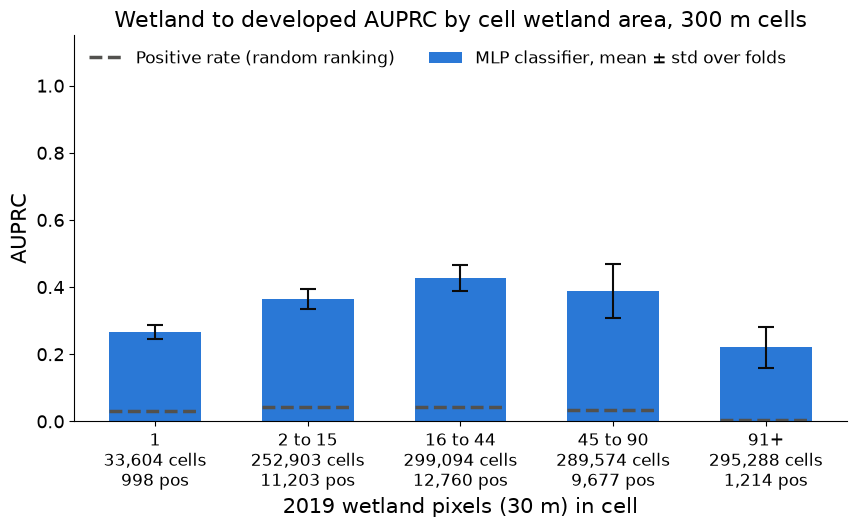

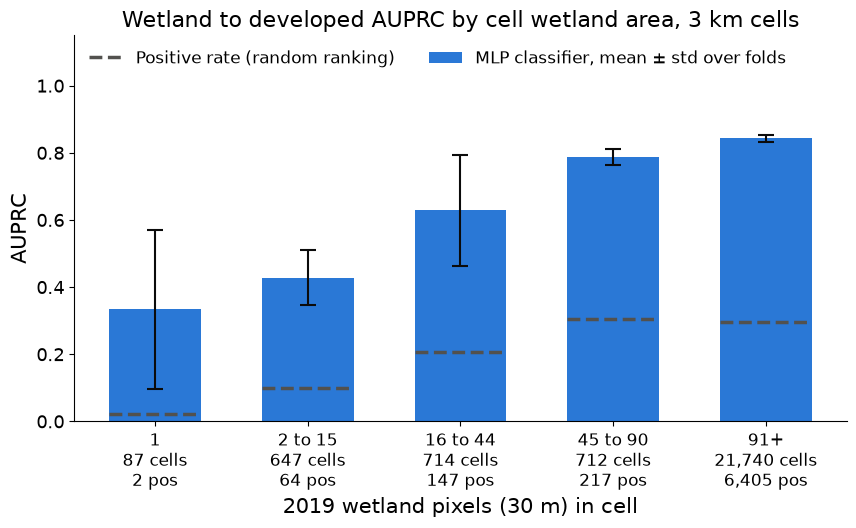

In [4]:
for res in RUNS:
    fig = plot_auprc_by_bin(summary[res], "2019 wetland pixels (30 m) in cell",
                            f"Wetland to developed AUPRC by cell wetland area, {RES_TITLE[res]}")
    fig.savefig(FIG_DIR / f"auprc_by_n_wetland_{res}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# AUPRC by quintile of 2019 wetland pixels per cell

Same classifier and same reading as above, but the bins are quintiles of `n_wetland` taken within each resolution, so each bar holds about a fifth of that resolution's validation cells. This fixes the problem with the shared bins, where a 3 km cell can hold up to 10,000 wetland pixels and nearly all of them landed in 91+.

These are computed straight from the per cell predictions in `fold_*/val_preds.npz`, not from the CSV. Quintile edges come from all validation cells pooled across the 5 folds (each cell is in exactly one validation fold), so every fold is scored on the same edges. Bars are the mean over folds and error bars the std across folds, as above.

`n_wetland` is an integer with a lot of ties (at 300 m the cell holds at most 100 pixels, and about 20% of cells are fully wetland at exactly 100), so the cut keeps tied cells in the same bin rather than splitting them to force exactly 20%. Bin sizes therefore differ by a few percent. At 300 m the top quintile is only the fully wetland cells.

In [5]:
from sklearn.metrics import average_precision_score


def load_val_preds(d):
    parts = []
    for p in sorted(d.glob("fold_*/val_preds.npz")):
        z = np.load(p)
        parts.append(pd.DataFrame({"fold": int(p.parent.name.split("_")[1]), "prob": z["prob"],
                                   "y": z["any"], "n_wetland": z["n_wetland"]}))
    return pd.concat(parts, ignore_index=True)


def quintile_labels(n, prefix="Q"):
    edges = np.quantile(n, [0.2, 0.4, 0.6, 0.8])
    assert np.unique(edges).size == 4, f"quintile edges collapse on ties: {edges}"
    # side="left" puts n == edge in the lower bin, so bin i is (edge[i-1], edge[i]]
    q = np.searchsorted(edges, n, side="left")
    # n is an integer, so write each bin as the integer range it actually covers
    lo = np.r_[n.min(), np.floor(edges) + 1].astype(int)
    hi = np.r_[np.floor(edges), n.max()].astype(int)
    names = [f"{prefix}{i + 1}\n{a:,}" if a == b else f"{prefix}{i + 1}\n{a:,} to {b:,}"
             for i, (a, b) in enumerate(zip(lo, hi))]
    return pd.Categorical.from_codes(q, names)


def summarize_bins(v, col):
    """Per fold AUPRC within each bin of v[col], then mean and std over folds."""
    per_fold = (v.groupby([col, "fold"], observed=True)
                 .apply(lambda g: pd.Series({
                     "n_cells": len(g), "n_pos": int(g["y"].sum()),
                     "auprc": average_precision_score(g["y"], g["prob"]) if g["y"].any() else np.nan}))
                 .reset_index())
    s = per_fold.groupby(col, observed=True).agg(
        n_cells=("n_cells", "sum"), n_pos=("n_pos", "sum"), folds_scored=("auprc", "count"),
        auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std"),
        auprc_min=("auprc", "min"), auprc_max=("auprc", "max"))
    s[["n_cells", "n_pos"]] = s[["n_cells", "n_pos"]].astype(int)
    s["positive_rate"] = s["n_pos"] / s["n_cells"]
    s.index = s.index.astype(str)
    return s


val_preds, quintile_summary = {}, {}
for res, d in RUNS.items():
    v = load_val_preds(d)
    assert len(v) == json.loads((d / "manifest.json").read_text())["cells"]["n_cells"]
    v["quintile"] = quintile_labels(v["n_wetland"].to_numpy())
    val_preds[res] = v

    s = summarize_bins(v, "quintile")
    quintile_summary[res] = s
    print(res)
    display(s.round(3))

300m


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 12,246170,10178,5,0.339,0.028,0.300,0.367,0.041
Q2\n13 to 31,227587,10100,5,0.430,0.033,0.382,0.469,0.044
Q3\n32 to 62,231811,9413,5,0.421,0.054,0.340,0.492,0.041
Q4\n63 to 99,233471,5824,5,0.342,0.092,0.225,0.482,0.025
Q5\n100,231424,337,5,0.125,0.036,0.077,0.167,0.001


3km


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 363,4792,1282,5,0.810,0.027,0.763,0.830,0.268
"Q2\n364 to 1,089",4787,1449,5,0.864,0.028,0.832,0.893,0.303
"Q3\n1,090 to 2,223",4762,1526,5,0.862,0.026,0.826,0.892,0.320
"Q4\n2,224 to 3,956",4779,1388,5,0.850,0.019,0.829,0.875,0.290
"Q5\n3,957 to 10,000",4780,1190,5,0.763,0.027,0.730,0.800,0.249


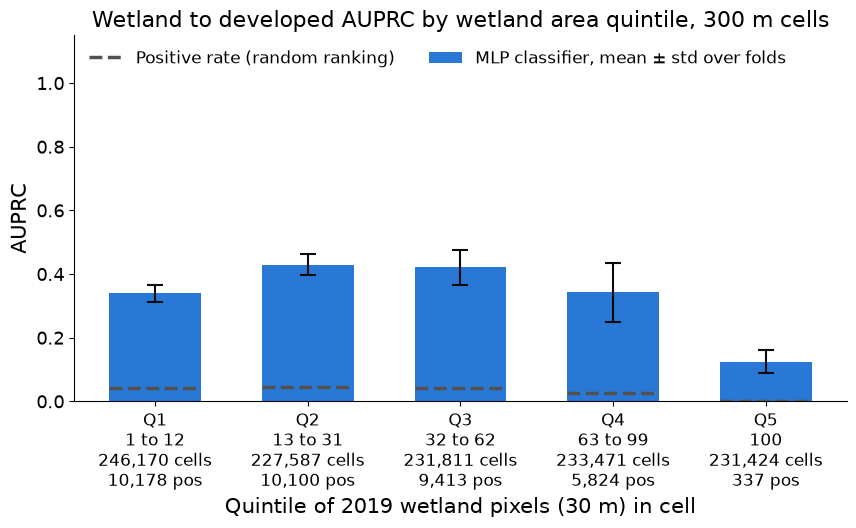

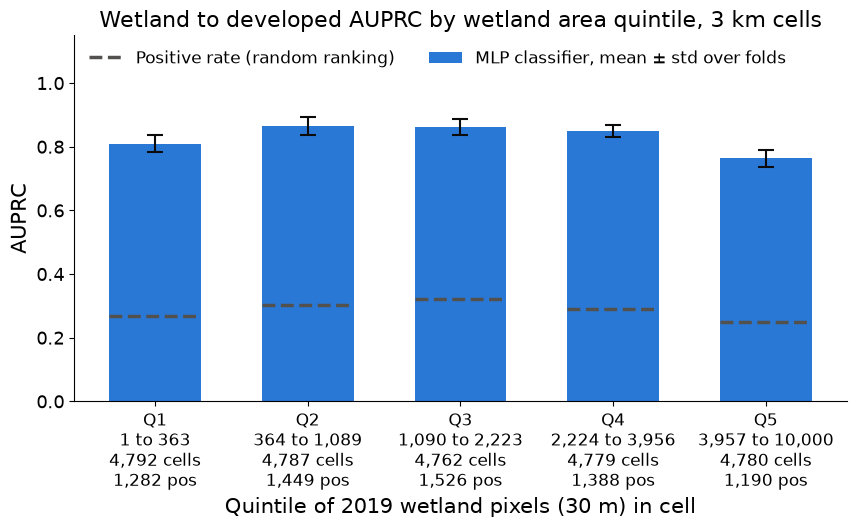

In [6]:
for res in RUNS:
    fig = plot_auprc_by_bin(quintile_summary[res], "Quintile of 2019 wetland pixels (30 m) in cell",
                            f"Wetland to developed AUPRC by wetland area quintile, {RES_TITLE[res]}")
    fig.savefig(FIG_DIR / f"auprc_by_n_wetland_quintile_{res}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# Confusion matrix for the top wetland area quintile (Q5)

TP, FP, TN and FN counts for the Q5 cells above: 100 wetland pixels (fully wetland) at 300 m, 3,957 to 10,000 pixels at 3 km.

The cut is each fold's own threshold from `manifest.json`, which is the highest probability that still reaches 50% recall on that fold's training cells. It is picked on train and carried to validation, so validation never sets its own cut. It is not 0.5, because the probabilities are not calibrated and a 0.5 cut means nothing here. The threshold is set on all training cells, not just Q5, so Q5 recall can sit well away from 50%.

Counts are summed over the 5 validation folds, each cell scored by its own fold's threshold. Cell color is the share of the actual class (row), so the rare converted row stays readable next to a TN count in the hundreds of thousands. The per fold table has the raw counts.

In [7]:
q5_counts = {}
for res, d in RUNS.items():
    thresholds = {int(k): f["threshold"] for k, f in json.loads((d / "manifest.json").read_text())["folds"].items()}
    v = val_preds[res]
    q5_label = v["quintile"].cat.categories[-1]
    q5 = v[v["quintile"] == q5_label].copy()
    q5["pred"] = q5["prob"] >= q5["fold"].map(thresholds)

    rows = []
    for k, g in q5.groupby("fold"):
        y, p = g["y"].to_numpy(), g["pred"].to_numpy()
        rows.append({"fold": k, "threshold": thresholds[k],
                     "TP": int((y & p).sum()), "FP": int((~y & p).sum()),
                     "TN": int((~y & ~p).sum()), "FN": int((y & ~p).sum())})
    t = pd.DataFrame(rows).set_index("fold")
    t.loc["all"] = t.sum()
    t.loc["all", "threshold"] = np.nan
    t[["TP", "FP", "TN", "FN"]] = t[["TP", "FP", "TN", "FN"]].astype(int)
    # a fold with no predicted positives gives 0/0 precision, left as NaN
    t["precision"] = t["TP"] / (t["TP"] + t["FP"]).replace(0, np.nan)
    t["recall"] = t["TP"] / (t["TP"] + t["FN"])
    t["positive_rate"] = (t["TP"] + t["FN"]) / t[["TP", "FP", "TN", "FN"]].sum(axis=1)
    q5_counts[res] = t
    print(f"{res}  Q5 = {q5_label.replace(chr(10), ': ')} wetland pixels, {len(q5):,} cells")
    display(t.round(3))

300m  Q5 = Q5: 100 wetland pixels, 231,424 cells


,threshold,TP,FP,TN,FN,precision,recall,positive_rate
fold,,,,,,,,
0,0.380,1,5,44289,58,0.167,0.017,0.001
1,0.363,7,18,48072,62,0.280,0.101,0.001
2,0.383,4,33,45828,73,0.108,0.052,0.002
3,0.354,4,2,47924,62,0.667,0.061,0.001
4,0.354,7,15,44901,59,0.318,0.106,0.001
all,NaN,23,73,231014,314,0.240,0.068,0.001


3km  Q5 = Q5: 3,957 to 10,000 wetland pixels, 4,780 cells


,threshold,TP,FP,TN,FN,precision,recall,positive_rate
fold,,,,,,,,
0,0.613,78,8,710,157,0.907,0.332,0.247
1,0.652,76,12,703,146,0.864,0.342,0.237
2,0.606,109,7,699,161,0.940,0.404,0.277
3,0.631,63,3,720,147,0.955,0.300,0.225
4,0.624,89,12,716,164,0.881,0.352,0.258
all,NaN,415,42,3548,775,0.908,0.349,0.249


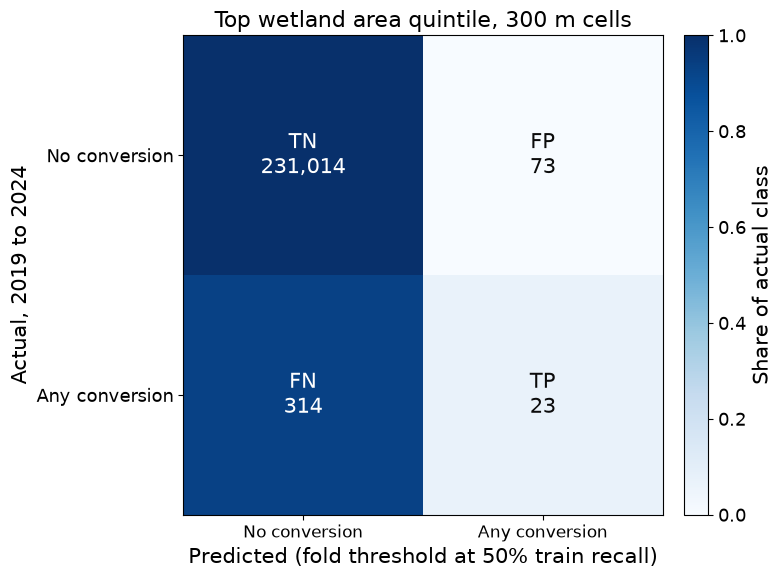

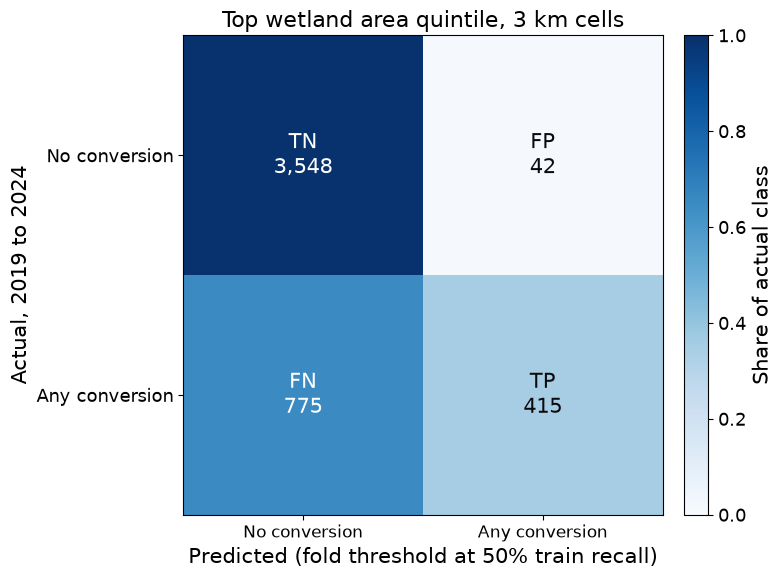

In [8]:
def plot_q5_confusion(t, title):
    a = t.loc["all"]
    # rows are actual, columns predicted, same layout as sklearn's confusion_matrix
    counts = np.array([[a["TN"], a["FP"]], [a["FN"], a["TP"]]], dtype=int)
    names = np.array([["TN", "FP"], ["FN", "TP"]])
    share = counts / counts.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(7.5, 6))
    im = ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i, j]}\n{counts[i, j]:,}", ha="center", va="center",
                    fontsize=15, color="white" if share[i, j] > 0.6 else "#0b0b0b")
    ax.set_xticks([0, 1], ["No conversion", "Any conversion"])
    ax.set_yticks([0, 1], ["No conversion", "Any conversion"])
    ax.set_xlabel("Predicted (fold threshold at 50% train recall)")
    ax.set_ylabel("Actual, 2019 to 2024")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Share of actual class")
    fig.tight_layout()
    return fig


for res in RUNS:
    fig = plot_q5_confusion(q5_counts[res], f"Top wetland area quintile, {RES_TITLE[res]}")
    fig.savefig(FIG_DIR / f"confusion_q5_{res}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# Splitting the 3 km top quintile further

The 3 km Q5 cells (3,957 to 10,000 wetland pixels) are split again into five equal count sub bins, Q5.1 to Q5.5, with the same rule as the quintiles above: edges taken from all Q5 validation cells pooled, tied pixel counts kept together. That gives 956 cells per sub bin. Equal counts were picked over fixed 1,000 pixel steps so every AUPRC is estimated from about the same number of cells (fixed steps would run from 393 to 1,197 cells).

Top panel is AUPRC, mean ± std over the 5 folds, with the positive rate as the gray line, read the same way as the bar charts above. Bottom panel is the cell count in each sub bin, split into cells with any conversion and cells with none.

Q5.5 has only 35 positives in total, 4 to 9 per fold, so its AUPRC and std are much noisier than the other sub bins.

In [9]:
v = val_preds["3km"]
q5_3km = v[v["quintile"] == v["quintile"].cat.categories[-1]].copy()
q5_3km["sub_bin"] = quintile_labels(q5_3km["n_wetland"].to_numpy(), prefix="Q5.")
q5_sub_summary = summarize_bins(q5_3km, "sub_bin")
display(q5_sub_summary.round(3))

,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
sub_bin,,,,,,,,
"Q5.1\n3,957 to 4,759",956,363,5,0.837,0.038,0.791,0.876,0.380
"Q5.2\n4,760 to 5,858",956,290,5,0.790,0.023,0.756,0.812,0.303
"Q5.3\n5,859 to 7,475",956,313,5,0.786,0.022,0.760,0.815,0.327
"Q5.4\n7,476 to 9,570",956,189,5,0.647,0.068,0.578,0.738,0.198
"Q5.5\n9,571 to 10,000",956,35,5,0.376,0.140,0.236,0.560,0.037


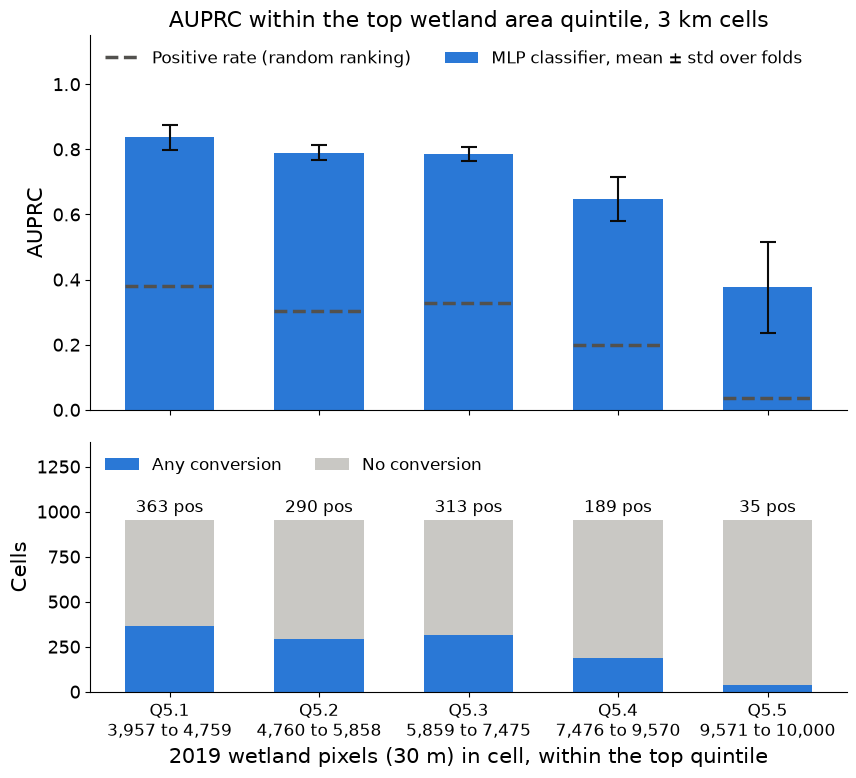

In [10]:
NEG_COLOR = "#c9c8c4"


def plot_auprc_and_positives(s, xlabel, title):
    x = np.arange(len(s))
    width = 0.6
    fig, (ax_a, ax_n) = plt.subplots(2, 1, figsize=(9, 8), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))

    ax_a.bar(x, s["auprc_mean"], width=width, color=BAR_COLOR, label="MLP classifier, mean ± std over folds",
             yerr=s["auprc_std"], error_kw=dict(ecolor="#0b0b0b", elinewidth=1.5, capsize=6, capthick=1.5),
             zorder=2)
    ax_a.hlines(s["positive_rate"], x - width / 2, x + width / 2, color=CHANCE_COLOR, lw=2.5, ls="--",
                label="Positive rate (random ranking)", zorder=3)
    ax_a.set_ylim(0, 1.15)
    ax_a.set_yticks(np.arange(0, 1.01, 0.2))
    ax_a.set_ylabel("AUPRC")
    ax_a.set_title(title)
    ax_a.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)

    n_neg = s["n_cells"] - s["n_pos"]
    ax_n.bar(x, s["n_pos"], width=width, color=BAR_COLOR, label="Any conversion", zorder=2)
    ax_n.bar(x, n_neg, width=width, bottom=s["n_pos"], color=NEG_COLOR, label="No conversion", zorder=2)
    for xi, (p, n) in enumerate(zip(s["n_pos"], s["n_cells"])):
        ax_n.text(xi, n * 1.02, f"{p:,} pos", ha="center", va="bottom", fontsize=12)
    ax_n.set_ylim(0, s["n_cells"].max() * 1.45)
    ax_n.set_ylabel("Cells")
    ax_n.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)

    ax_n.set_xticks(x, s.index)
    ax_n.set_xlabel(xlabel)
    for ax in (ax_a, ax_n):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    fig.tight_layout()
    return fig


fig = plot_auprc_and_positives(q5_sub_summary, "2019 wetland pixels (30 m) in cell, within the top quintile",
                               "AUPRC within the top wetland area quintile, 3 km cells")
fig.savefig(FIG_DIR / "auprc_q5_sub_bins_3km.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()